In [2]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from sklearn.preprocessing import MinMaxScaler
from sklearn.metrics import mean_absolute_error, mean_squared_error
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import LSTM, Dense
from tensorflow.keras.callbacks import EarlyStopping
import os
os.environ['TF_CPP_MIN_LOG_LEVEL'] = '3'

df = pd.read_csv("../data_processed/metro_trips_model_ready.csv", parse_dates=['date'])

station = "BurJuman Metro Station"
s = df[df['metro_station'] == station].set_index('date')['trips'].asfreq('MS')
s = s.interpolate(method='linear').bfill().ffill()  # same gap-handling as SARIMA, for fair comparison
print(s.shape)
print("NaN count:", s.isna().sum())

(68,)
NaN count: 0


In [3]:
scaler = MinMaxScaler()
scaled = scaler.fit_transform(s.values.reshape(-1, 1))

def make_sequences(data, window=12):
    X, y = [], []
    for i in range(len(data) - window):
        X.append(data[i:i+window])
        y.append(data[i+window])
    return np.array(X), np.array(y)

window = 12
X, y = make_sequences(scaled, window=window)
print("X shape:", X.shape)
print("y shape:", y.shape)

# Same 6-month holdout as SARIMA, for fair comparison
holdout = 6
X_train, y_train = X[:-holdout], y[:-holdout]
X_test, y_test = X[-holdout:], y[-holdout:]
print("Train:", X_train.shape, "Test:", X_test.shape)

X shape: (56, 12, 1)
y shape: (56, 1)
Train: (50, 12, 1) Test: (6, 12, 1)


In [4]:
model = Sequential([
    LSTM(50, activation='relu', input_shape=(window, 1)),
    Dense(1)
])
model.compile(optimizer='adam', loss='mse')

early_stop = EarlyStopping(monitor='loss', patience=15, restore_best_weights=True)

history = model.fit(X_train, y_train, epochs=200, batch_size=8, 
                     callbacks=[early_stop], verbose=0)

print("Training stopped at epoch:", len(history.history['loss']))
print("Final training loss:", history.history['loss'][-1])

Training stopped at epoch: 81
Final training loss: 0.013558217324316502


LSTM - MAE: 143454  RMSE: 166000  MAPE: 9.1%

SARIMA (final, same station/holdout): MAPE = 4.8%


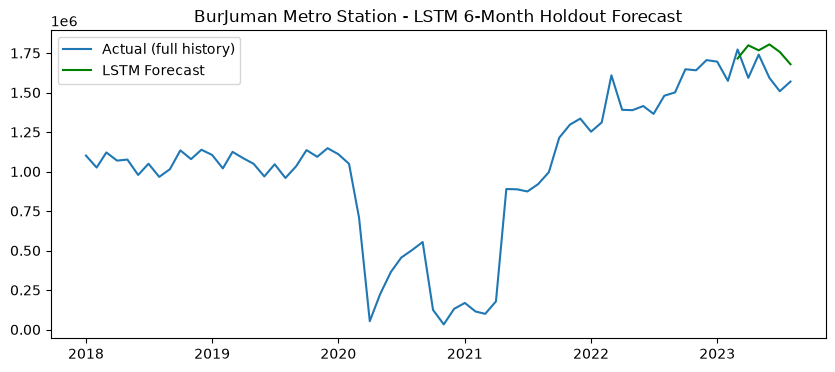

In [5]:
predictions_scaled = model.predict(X_test, verbose=0)
predictions = scaler.inverse_transform(predictions_scaled)
actual = scaler.inverse_transform(y_test)

mae = mean_absolute_error(actual, predictions)
rmse = np.sqrt(mean_squared_error(actual, predictions))
mape = (abs((actual - predictions) / actual)).mean() * 100

print(f"LSTM - MAE: {mae:.0f}  RMSE: {rmse:.0f}  MAPE: {mape:.1f}%")

# Compare directly against SARIMA's result for the same station (from Phase 3)
print(f"\nSARIMA (final, same station/holdout): MAPE = 4.8%")

plt.figure(figsize=(10,4))
test_dates = s.index[-holdout:]
plt.plot(s.index, s.values, label='Actual (full history)')
plt.plot(test_dates, predictions.flatten(), label='LSTM Forecast', color='green')
plt.legend()
plt.title(f"{station} - LSTM 6-Month Holdout Forecast")
plt.savefig("../docs/lstm_01_burjuman_holdout.png", dpi=150, bbox_inches='tight')
plt.show()

In [6]:
mape_runs = []
for run in range(5):
    model_run = Sequential([LSTM(50, activation='relu', input_shape=(window, 1)), Dense(1)])
    model_run.compile(optimizer='adam', loss='mse')
    model_run.fit(X_train, y_train, epochs=200, batch_size=8, 
                  callbacks=[EarlyStopping(monitor='loss', patience=15, restore_best_weights=True)], 
                  verbose=0)
    pred = scaler.inverse_transform(model_run.predict(X_test, verbose=0))
    mape_run = (abs((actual - pred) / actual)).mean() * 100
    mape_runs.append(mape_run)
    print(f"Run {run+1}: MAPE = {mape_run:.1f}%")

print(f"\nMean MAPE across 5 runs: {np.mean(mape_runs):.1f}%  Std: {np.std(mape_runs):.1f}%")

Run 1: MAPE = 17.8%
Run 2: MAPE = 14.2%
Run 3: MAPE = 9.0%
Run 4: MAPE = 25.1%
Run 5: MAPE = 9.9%

Mean MAPE across 5 runs: 15.2%  Std: 5.9%


In [7]:
import time

def build_and_evaluate_lstm(series, station_name, window=12, holdout=6, n_runs=3, epochs=200, min_months=24):
    had_nans = series.isna().sum()
    series_clean = series.interpolate(method='linear').bfill().ffill()
    
    if len(series_clean) < min_months + window + holdout:
        return {'station': station_name, 'status': 'insufficient_data', 'n_months': len(series_clean)}
    
    scaler = MinMaxScaler()
    scaled = scaler.fit_transform(series_clean.values.reshape(-1, 1))
    
    X, y = make_sequences(scaled, window=window)
    if len(X) <= holdout + 10:  # need reasonable training set
        return {'station': station_name, 'status': 'insufficient_sequences', 'n_sequences': len(X)}
    
    X_train, y_train = X[:-holdout], y[:-holdout]
    X_test, y_test = X[-holdout:], y[-holdout:]
    actual = scaler.inverse_transform(y_test)
    
    run_predictions = []
    for run in range(n_runs):
        m = Sequential([LSTM(50, activation='relu', input_shape=(window, 1)), Dense(1)])
        m.compile(optimizer='adam', loss='mse')
        m.fit(X_train, y_train, epochs=epochs, batch_size=8,
              callbacks=[EarlyStopping(monitor='loss', patience=15, restore_best_weights=True)], verbose=0)
        pred = scaler.inverse_transform(m.predict(X_test, verbose=0))
        run_predictions.append(pred.flatten())
    
    avg_pred = np.mean(run_predictions, axis=0).reshape(-1,1)
    mape = (abs((actual - avg_pred) / actual)).mean() * 100
    rmse = np.sqrt(mean_squared_error(actual, avg_pred))
    mae = mean_absolute_error(actual, avg_pred)
    mape_std = np.std([(abs((actual.flatten() - p) / actual.flatten())).mean() * 100 for p in run_predictions])
    
    # Final model: train once more on FULL data for deployment
    X_full, y_full = make_sequences(scaled, window=window)
    final_model = Sequential([LSTM(50, activation='relu', input_shape=(window, 1)), Dense(1)])
    final_model.compile(optimizer='adam', loss='mse')
    final_model.fit(X_full, y_full, epochs=epochs, batch_size=8,
                     callbacks=[EarlyStopping(monitor='loss', patience=15, restore_best_weights=True)], verbose=0)
    
    return {
        'station': station_name, 'status': 'ok', 'holdout_MAPE': mape, 'holdout_RMSE': rmse, 'holdout_MAE': mae,
        'mape_std_across_runs': mape_std, 'interpolated_months': int(had_nans),
        'n_months': len(series_clean), 'model': final_model, 'scaler': scaler
    }

# Quick test on BurJuman to confirm the function matches our manual result
t0 = time.time()
test_lstm = build_and_evaluate_lstm(s, station)
print(f"Took {time.time()-t0:.0f}s")
print(f"MAPE: {test_lstm['holdout_MAPE']:.1f}%  (std across runs: {test_lstm['mape_std_across_runs']:.1f}%)")

Took 50s
MAPE: 8.5%  (std across runs: 2.5%)


In [8]:
import warnings
warnings.filterwarnings('ignore')

all_stations = df['metro_station'].unique()
lstm_results = {}
t0 = time.time()

for i, st in enumerate(all_stations):
    series = df[df['metro_station'] == st].set_index('date')['trips'].asfreq('MS')
    result = build_and_evaluate_lstm(series, st)
    lstm_results[st] = result
    elapsed = time.time() - t0
    status = result.get('status')
    if status == 'ok':
        print(f"[{i+1}/53] ({elapsed:.0f}s) {st}: MAPE={result['holdout_MAPE']:.1f}% (std={result['mape_std_across_runs']:.1f}%)")
    else:
        print(f"[{i+1}/53] ({elapsed:.0f}s) {st}: {status}")

print(f"\nTotal time: {(time.time()-t0)/60:.1f} minutes")

[1/53] (52s) ADCB Metro Station: MAPE=12.6% (std=3.2%)
[2/53] (94s) Abu Baker Al Siddique Metro Station: MAPE=6.4% (std=1.1%)
[3/53] (148s) Abu Hail Metro Station: MAPE=7.7% (std=0.5%)
[4/53] (205s) Airport Terminal 1 Metro Station: MAPE=8.8% (std=0.7%)
[5/53] (260s) Airport Terminal 3 Metro Station: MAPE=11.1% (std=0.2%)
[6/53] (321s) Al Fahidi Metro Station: MAPE=8.5% (std=3.2%)
[7/53] (360s) Al Furjan Metro Station: MAPE=9.2% (std=0.7%)
[8/53] (399s) Al Ghubaiba Metro Station: MAPE=11.9% (std=4.5%)
[9/53] (449s) Al Jadaf Metro Station: MAPE=22.3% (std=4.0%)
[10/53] (506s) Al Jafiliya Metro Station: MAPE=7.9% (std=0.7%)
[11/53] (552s) Al Nahda Metro Station: MAPE=10.6% (std=1.5%)
[12/53] (576s) Al Qiyadah Metro Station: MAPE=17.7% (std=3.8%)
[13/53] (613s) Al Qusais Metro Station: MAPE=13.2% (std=1.6%)
[14/53] (641s) Al Ras Metro Station: MAPE=14.3% (std=5.8%)
[15/53] (681s) Al Rigga Metro Station: MAPE=10.0% (std=2.4%)
[16/53] (735s) Baniyas Square Metro Station: MAPE=5.8% (std=0.6%

In [9]:
lstm_summary = []
for st, r in lstm_results.items():
    if r.get('status') == 'ok':
        lstm_summary.append({'station': st, 'MAPE_lstm': r['holdout_MAPE'], 'std_across_runs': r['mape_std_across_runs']})
    else:
        lstm_summary.append({'station': st, 'MAPE_lstm': None, 'status': r.get('status')})

lstm_df = pd.DataFrame(lstm_summary)
ok_lstm = lstm_df[lstm_df['MAPE_lstm'].notna()]

print("Stations with valid LSTM result:", len(ok_lstm))
print("Mean MAPE:", ok_lstm['MAPE_lstm'].mean().round(1))
print("Median MAPE:", ok_lstm['MAPE_lstm'].median().round(1))
print("\nTop 8 worst MAPE:")
print(ok_lstm.sort_values('MAPE_lstm', ascending=False).head(8))

# Check the actual trip values for Energy, Jumeirah Golf Estates, Nakheel around their holdout period
for st in ['Energy Metro Station', 'Jumeirah Golf Estates Metro Station', 'Nakheel Metro Station']:
    series = df[df['metro_station']==st].set_index('date')['trips'].asfreq('MS')
    print(f"\n{st} last 8 months:")
    print(series.tail(8))

Stations with valid LSTM result: 51
Mean MAPE: 24.4
Median MAPE: 12.4

Top 8 worst MAPE:
                                station   MAPE_lstm  std_across_runs status
29                   EXPO Metro Station  435.094539        74.085492    NaN
32                 Energy Metro Station   90.396965         5.358792    NaN
40  Jumeirah Golf Estates Metro Station   61.161913         8.286454    NaN
43                Nakheel Metro Station   35.882773        11.637621    NaN
31        Emirates Towers Metro Station   27.061943         3.423410    NaN
19                  Creek Metro Station   25.747010         2.339264    NaN
27    Dubai Internet City Metro Station   23.710937         4.328401    NaN
8                Al Jadaf Metro Station   22.296642         3.978577    NaN

Energy Metro Station last 8 months:
date
2023-01-01    43182
2023-02-01    38558
2023-03-01    40899
2023-04-01    51805
2023-05-01    36140
2023-06-01    38919
2023-07-01    31376
2023-08-01    30621
Freq: MS, Name: trips, dt

In [10]:
energy_series = df[df['metro_station']=='Energy Metro Station'].set_index('date')['trips'].asfreq('MS')
energy_series = energy_series.interpolate(method='linear').bfill().ffill()

scaler_e = MinMaxScaler()
scaled_e = scaler_e.fit_transform(energy_series.values.reshape(-1,1))
X_e, y_e = make_sequences(scaled_e, window=12)
X_test_e, y_test_e = X_e[-6:], y_e[-6:]
actual_e = scaler_e.inverse_transform(y_test_e)

pred_e = lstm_results['Energy Metro Station']['model'].predict(X_test_e, verbose=0)
pred_e_actual = scaler_e.inverse_transform(pred_e)

print("Actual:", actual_e.flatten())
print("Predicted:", pred_e_actual.flatten())

Actual: [40899. 51805. 36140. 38919. 31376. 30621.]
Predicted: [43011.32  42125.824 44979.555 38781.613 35238.453 29571.521]


In [11]:
result_e = lstm_results['Energy Metro Station']
print("Reported MAPE:", result_e['holdout_MAPE'])

# Manually recompute using the SAME train/test split the function used
series_e = df[df['metro_station']=='Energy Metro Station'].set_index('date')['trips'].asfreq('MS')
series_e_clean = series_e.interpolate(method='linear').bfill().ffill()
print("\nLast 10 raw values used:")
print(series_e_clean.tail(10))

scaler_check = MinMaxScaler()
scaled_check = scaler_check.fit_transform(series_e_clean.values.reshape(-1,1))
X_check, y_check = make_sequences(scaled_check, window=12)
print("\nTotal sequences:", len(X_check))
y_test_check = y_check[-6:]
actual_check = scaler_check.inverse_transform(y_test_check)
print("Actual (recomputed):", actual_check.flatten())

Reported MAPE: 90.39696455407275

Last 10 raw values used:
date
2022-11-01    31927
2022-12-01    43651
2023-01-01    43182
2023-02-01    38558
2023-03-01    40899
2023-04-01    51805
2023-05-01    36140
2023-06-01    38919
2023-07-01    31376
2023-08-01    30621
Freq: MS, Name: trips, dtype: int64

Total sequences: 56
Actual (recomputed): [40899. 51805. 36140. 38919. 31376. 30621.]


In [12]:
train_check = X_check[:-6]
y_train_check = y_check[:-6]

run_preds_debug = []
for run in range(3):
    m = Sequential([LSTM(50, activation='relu', input_shape=(12, 1)), Dense(1)])
    m.compile(optimizer='adam', loss='mse')
    m.fit(train_check, y_train_check, epochs=200, batch_size=8,
          callbacks=[EarlyStopping(monitor='loss', patience=15, restore_best_weights=True)], verbose=0)
    pred = scaler_check.inverse_transform(m.predict(X_check[-6:], verbose=0))
    run_preds_debug.append(pred.flatten())
    print(f"Run {run+1} predictions: {pred.flatten()}")

avg_debug = np.mean(run_preds_debug, axis=0)
print("\nAveraged predictions:", avg_debug)
print("Actual:             ", actual_check.flatten())

mape_debug = (abs((actual_check.flatten() - avg_debug) / actual_check.flatten())).mean() * 100
print("\nRecomputed MAPE:", mape_debug)

Run 1 predictions: [47560.11  52275.902 61045.94  62927.316 74839.15  83905.516]
Run 2 predictions: [ 55578.336  64210.14   78528.75   91791.26  116107.91  145203.55 ]
Run 3 predictions: [50112.13 56343.45 66912.84 72134.67 79611.31 83489.25]

Averaged predictions: [ 51083.527  57609.832  68829.18   75617.75   90186.125 104199.44 ]
Actual:              [40899. 51805. 36140. 38919. 31376. 30621.]

Recomputed MAPE: 108.09628295888373


In [13]:
import pickle
import os

os.makedirs("../models/lstm", exist_ok=True)

saved_count = 0
for st, r in lstm_results.items():
    if r.get('status') == 'ok':
        safe_name = st.replace('/', '_').replace(' ', '_')
        r['model'].save(f"../models/lstm/{safe_name}.keras")
        with open(f"../models/lstm/{safe_name}_scaler.pkl", "wb") as f:
            pickle.dump(r['scaler'], f)
        saved_count += 1

print(f"Saved {saved_count} LSTM models + scalers.")

lstm_df.to_csv("../docs/lstm_results_summary.csv", index=False)
print("Saved LSTM results summary.")

Saved 51 LSTM models + scalers.
Saved LSTM results summary.


# Note for dissertation write-up:
# Discovery Gardens Metro Station and The Gardens Metro Station (both Route 2020 branch, 
# opened 2020) were excluded from LSTM modelling due to insufficient history (40 months each, 
# below the 42-month minimum required for a 12-month sliding window + 24-month minimum training 
# floor + 6-month holdout). Both were successfully modelled by SARIMA (MAPE 7.9% and 7.5% 
# respectively), illustrating that LSTM's sequence-based architecture requires more historical 
# data than classical statistical approaches to be reliably applied - a genuine trade-off worth 
# noting when selecting a forecasting method for a transit network with stations of varying age.
print("Documented: 2/53 stations excluded from LSTM (insufficient history), covered by SARIMA instead.")

In [14]:
lstm_summary_full = []
for st, r in lstm_results.items():
    if r.get('status') == 'ok':
        lstm_summary_full.append({
            'station': st, 'MAPE_lstm': r['holdout_MAPE'], 'RMSE_lstm': r['holdout_RMSE'], 'MAE_lstm': r['holdout_MAE'],
            'std_across_runs': r['mape_std_across_runs']
        })
    else:
        lstm_summary_full.append({'station': st, 'MAPE_lstm': None, 'RMSE_lstm': None, 'MAE_lstm': None, 'status': r.get('status')})

lstm_full_df = pd.DataFrame(lstm_summary_full)
lstm_full_df.to_csv("../docs/lstm_results_summary.csv", index=False)
print("Re-saved with RMSE/MAE:", lstm_full_df.shape)
print(lstm_full_df.head())

Re-saved with RMSE/MAE: (53, 6)
                               station  MAPE_lstm      RMSE_lstm  \
0                   ADCB Metro Station  12.622782  121623.729816   
1  Abu Baker Al Siddique Metro Station   6.390319   39116.715974   
2               Abu Hail Metro Station   7.728266   30394.575702   
3     Airport Terminal 1 Metro Station   8.779451   32810.237802   
4     Airport Terminal 3 Metro Station  11.077012   23649.900811   

        MAE_lstm  std_across_runs status  
0  106413.666667         3.248905    NaN  
1   33405.619792         1.067915    NaN  
2   27715.536458         0.485279    NaN  
3   28076.302083         0.711506    NaN  
4   20815.739583         0.221644    NaN  
